# Análisis de Confusiones entre señas 



In [2]:
from pathlib import Path
import json
import importlib.util
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.2

# Busca landmark_recognition desde el directorio de trabajo o sus padres.
PROJECT_DIR = None
for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "data" / "landmarks_intersection.npz").is_file() and (candidate / "class_labels.py").is_file():
        PROJECT_DIR = candidate
        break
    nested = candidate / "landmark_recognition"
    if (nested / "data" / "landmarks_intersection.npz").is_file():
        PROJECT_DIR = nested
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("No se encontró landmark_recognition/data/landmarks_intersection.npz. Abre el notebook desde el proyecto Fase 2.")

CODE_DIR = PROJECT_DIR.parent
DATASET_PATH = PROJECT_DIR / "data" / "landmarks_intersection.npz"
SUMMARY_PATH = PROJECT_DIR / "reports" / "courtesy_intersection" / "training_summary.json"
PREFERRED_CHECKPOINT_PATH = Path(r"D:\Noveno\Fase 2\LSC\FASE 2\Codigo\landmark_recognition\checkpoints\transformer_intersection.pth")
CHECKPOINT_PATH = PREFERRED_CHECKPOINT_PATH if PREFERRED_CHECKPOINT_PATH.is_file() else PROJECT_DIR / "checkpoints" / "transformer_intersection.pth"

required_files = [DATASET_PATH, SUMMARY_PATH, CHECKPOINT_PATH]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Faltan artefactos requeridos:\n" + "\n".join(missing_files))

with np.load(DATASET_PATH, allow_pickle=False) as archive:
    X = archive["X"].astype(np.float32)
    y = archive["y"].astype(np.int64)
    signers = archive["signers"].astype(str)
    class_codes = archive["class_names"].astype(str).tolist()
with SUMMARY_PATH.open(encoding="utf-8") as handle:
    training_summary = json.load(handle)

label_spec = importlib.util.spec_from_file_location("phase2_class_labels", PROJECT_DIR / "class_labels.py")
label_module = importlib.util.module_from_spec(label_spec)
label_spec.loader.exec_module(label_module)
display_name = label_module.display_class_name
class_index = {code: index for index, code in enumerate(class_codes)}

print(f"Proyecto: {PROJECT_DIR}")
print(f"Checkpoint evaluado: {CHECKPOINT_PATH}")
print(f"Dataset: X={X.shape}, y={y.shape}, firmantes={len(set(signers))}, clases={len(class_codes)}")

Proyecto: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition
Checkpoint evaluado: D:\Noveno\Fase 2\LSC\FASE 2\Codigo\landmark_recognition\checkpoints\transformer_intersection.pth
Dataset: X=(997, 64, 75, 3), y=(997,), firmantes=23, clases=17


## 1. Cargar el checkpoint 



In [3]:
import sys
sys.path.insert(0, str(CODE_DIR))
import torch
from landmark_recognition.inference import load_checkpoint_model, prepare_checkpoint_features

test_signer = str(training_summary["test_signer"])
validation_signer = str(training_summary["validation_signer"])
if test_signer == validation_signer:
    raise ValueError("El firmante de validación no puede ser el mismo que el de prueba.")
test_mask = signers == test_signer
train_signers = sorted(set(signers) - {test_signer, validation_signer})
train_mask = np.isin(signers, train_signers)
test_indices = np.flatnonzero(test_mask)
if len(test_indices) != int(training_summary["test_count"]):
    raise ValueError("El número de secuencias del firmante de prueba no coincide con el resumen guardado.")
if X.ndim != 4 or X.shape[2:] != (75, 3) or len(X) != len(y) or len(y) != len(signers):
    raise ValueError(f"Forma inesperada o arrays desalineados: X={X.shape}, y={y.shape}, signers={signers.shape}")

model, checkpoint = load_checkpoint_model(CHECKPOINT_PATH, torch.device("cpu"))
checkpoint_classes = [str(code) for code in checkpoint["class_names"]]
if checkpoint_classes != class_codes:
    raise ValueError("El orden de clases del checkpoint no coincide con class_names del dataset.")

test_features = np.stack([prepare_checkpoint_features(X[index], checkpoint) for index in test_indices])
with torch.inference_mode():
    logits = model(torch.from_numpy(test_features))
probabilities = torch.softmax(logits, dim=1).cpu().numpy()
test_predictions = logits.argmax(dim=1).cpu().numpy()
test_targets = y[test_indices]
accuracy = float(np.mean(test_predictions == test_targets))
errors = []
for position, (sample_index, target, prediction) in enumerate(zip(test_indices, test_targets, test_predictions)):
    if target != prediction:
        errors.append({
            "sample_index": int(sample_index),
            "true_class": class_codes[int(target)],
            "predicted_class": class_codes[int(prediction)],
            "confidence": float(probabilities[position, prediction]),
        })

print(f"Arquitectura: {checkpoint['architecture']}; split: firmante reservado")
print(f"Validación: {validation_signer}; prueba: {test_signer}")
print(f"Firmantes usados para entrenamiento: {len(train_signers)}")
print(f"Aciertos: {len(test_indices) - len(errors)}/{len(test_indices)}; accuracy recalculada={accuracy:.3f}")
print(f"Accuracy del resumen guardado={training_summary['test_accuracy']:.3f}; F1 macro reportado={training_summary['macro_f1']:.3f}")
if abs(accuracy - float(training_summary["test_accuracy"])) > 1e-6:
    print("AVISO: la accuracy recalculada no coincide con el resumen; revisa que checkpoint, dataset y configuración pertenezcan a la misma corrida.")
print(f"Con {len(test_indices)} casos, un error cambia la accuracy en {100 / len(test_indices):.2f} puntos porcentuales.")

Arquitectura: transformer; split: firmante reservado
Validación: courtesy_videos::0024; prueba: courtesy_videos::0025
Firmantes usados para entrenamiento: 21
Aciertos: 46/51; accuracy recalculada=0.902
Accuracy del resumen guardado=0.902; F1 macro reportado=0.892
Con 51 casos, un error cambia la accuracy en 1.96 puntos porcentuales.


D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\models.py:62: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=layers)


## 2. Matriz de confusión y desempeño por clase

Las filas representan la clase real y las columnas la predicción del checkpoint.

Confusiones dirigidas (real → predicha):
  MÁS O MENOS (0027) → CHAO (0051): 2/3 casos reales
  PERMISO (0036) → DE NADA (0052): 2/3 casos reales
  BUENAS TARDES (0002) → BUENAS NOCHES (0003): 1/3 casos reales

Métricas por clase (el soporte de prueba es pequeño):
GRACIAS              0000 | n= 3 | precision=1.00 recall=1.00 F1=1.00
BUENOS DÍAS          0001 | n= 3 | precision=1.00 recall=1.00 F1=1.00
BUENAS TARDES        0002 | n= 3 | precision=1.00 recall=0.67 F1=0.80
BUENAS NOCHES        0003 | n= 3 | precision=0.75 recall=1.00 F1=0.86
BIEN                 0024 | n= 3 | precision=1.00 recall=1.00 F1=1.00
MAL                  0025 | n= 3 | precision=1.00 recall=1.00 F1=1.00
MÁS O MENOS          0027 | n= 3 | precision=1.00 recall=0.33 F1=0.50
HOLA                 0030 | n= 3 | precision=1.00 recall=1.00 F1=1.00
POR FAVOR            0032 | n= 3 | precision=1.00 recall=1.00 F1=1.00
CON GUSTO            0033 | n= 3 | precision=1.00 recall=1.00 F1=1.00
BIENVENIDO           0034 | n= 3 | 

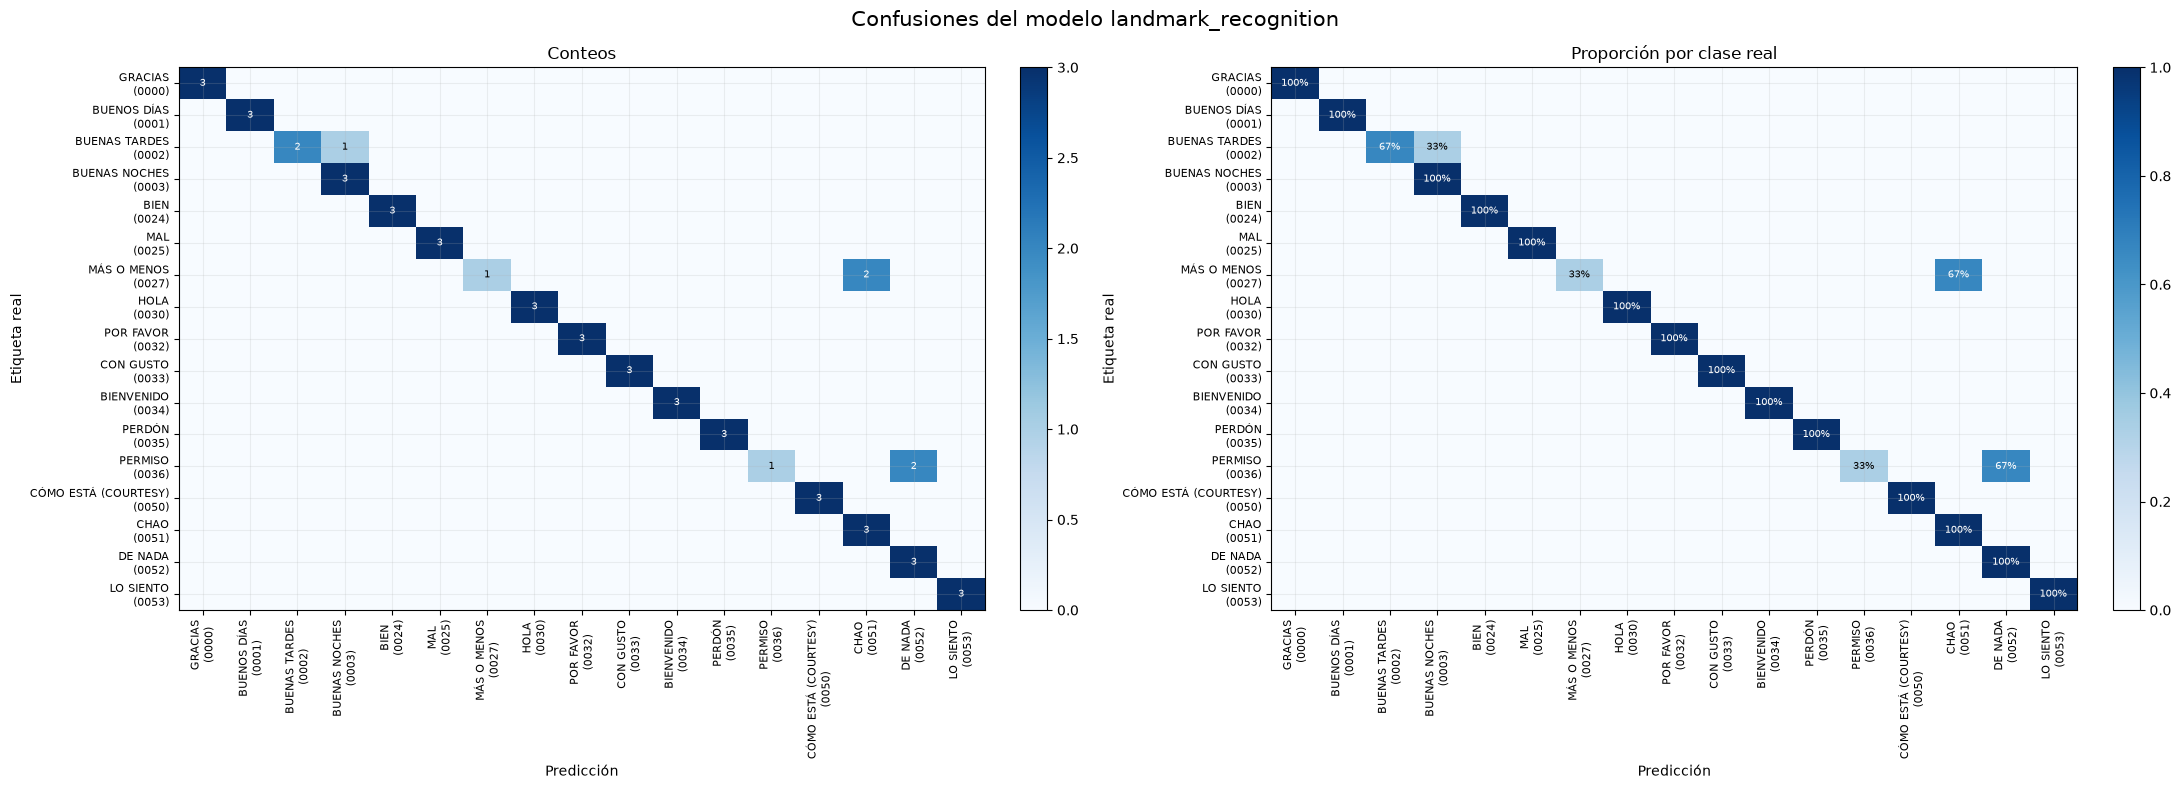

In [4]:
confusion = np.zeros((len(class_codes), len(class_codes)), dtype=np.int64)
np.add.at(confusion, (test_targets, test_predictions), 1)
support = confusion.sum(axis=1)
predicted_count = confusion.sum(axis=0)
true_positive = np.diag(confusion)
precision = np.divide(true_positive, predicted_count, out=np.zeros(len(class_codes), dtype=float), where=predicted_count != 0)
recall = np.divide(true_positive, support, out=np.zeros(len(class_codes), dtype=float), where=support != 0)
f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(class_codes), dtype=float), where=(precision + recall) != 0)
row_rate = np.divide(confusion, support[:, None], out=np.zeros_like(confusion, dtype=float), where=support[:, None] != 0)
labels = [f"{display_name(code)}\n({code})" for code in class_codes]

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, matrix, title, fmt, vmax in [
    (axes[0], confusion, "Conteos", "d", max(1, int(confusion.max()))),
    (axes[1], row_rate, "Proporción por clase real", ".0%", 1.0),
]:
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set(title=title, xlabel="Predicción", ylabel="Etiqueta real", xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=labels, yticklabels=labels)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            if matrix[i, j] > 0:
                ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", fontsize=7, color="white" if matrix[i, j] > vmax * 0.55 else "black")
fig.suptitle("Confusiones del modelo landmark_recognition", fontsize=15)
fig.tight_layout()

pair_counts = Counter((error["true_class"], error["predicted_class"]) for error in errors)
top_pairs = pair_counts.most_common()
print("Confusiones dirigidas (real → predicha):")
for (true_code, predicted_code), count in top_pairs:
    class_support = int(confusion[class_index[true_code]].sum())
    print(f"  {display_name(true_code)} ({true_code}) → {display_name(predicted_code)} ({predicted_code}): {count}/{class_support} casos reales")
print("\nMétricas por clase (el soporte de prueba es pequeño):")
for i, code in enumerate(class_codes):
    print(f"{display_name(code):20s} {code} | n={support[i]:2d} | precision={precision[i]:.2f} recall={recall[i]:.2f} F1={f1[i]:.2f}")
print(f"\nF1 macro recalculado={f1.mean():.3f}")

## 3. Inspección visual de los errores

Para los pares más confundidos se muestra una secuencia mal clasificada y ejemplos de referencia de ambas clases tomados del entrenamiento. Cada fila representa una secuencia en tres momentos: inicio, mitad y final. Los puntos faltantes se omiten; el origen (0,0) no debe interpretarse como una articulación observada.

Índice(s) de error: [582, 584]; firmante=courtesy_videos::0025


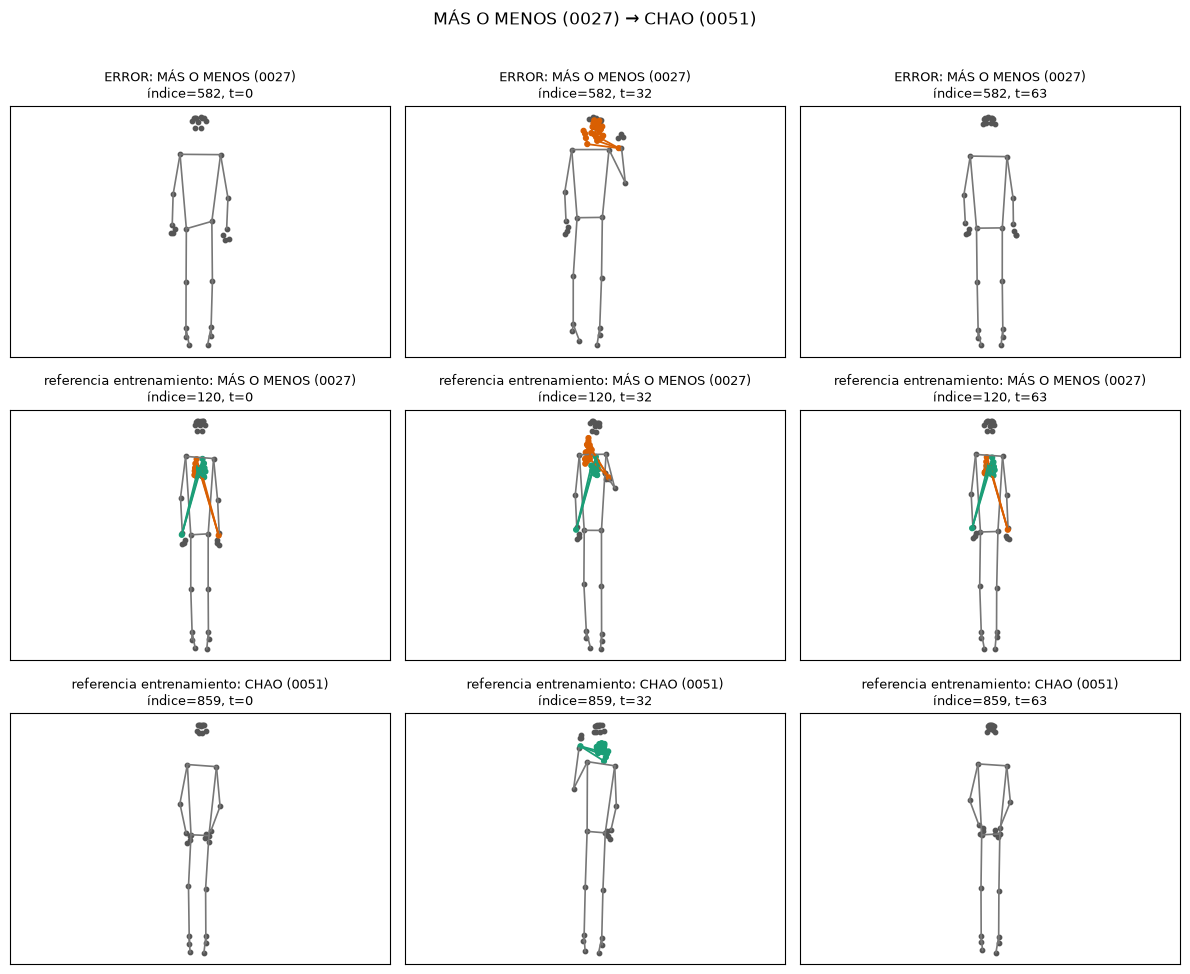

Índice(s) de error: [827, 829]; firmante=courtesy_videos::0025


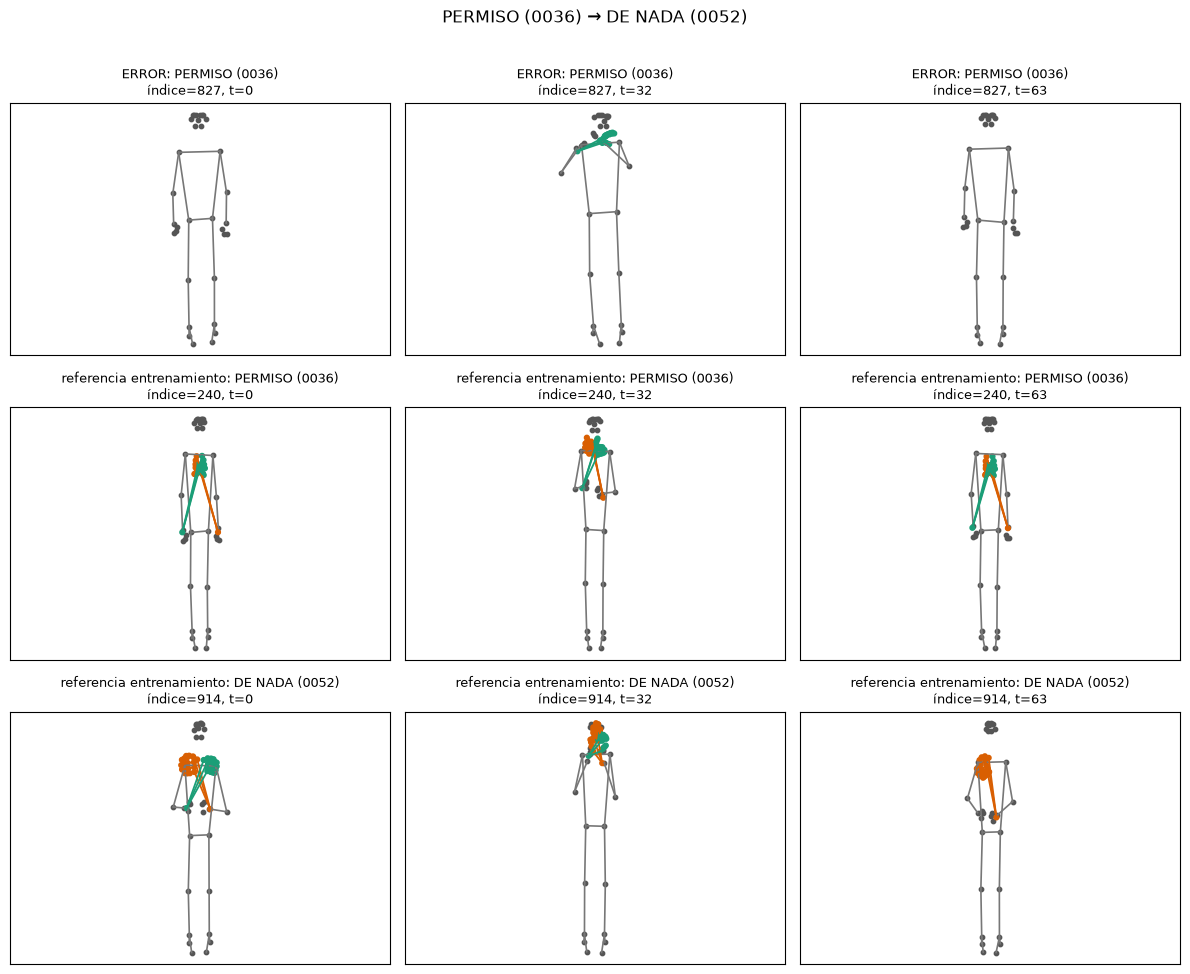

Índice(s) de error: [366]; firmante=courtesy_videos::0025


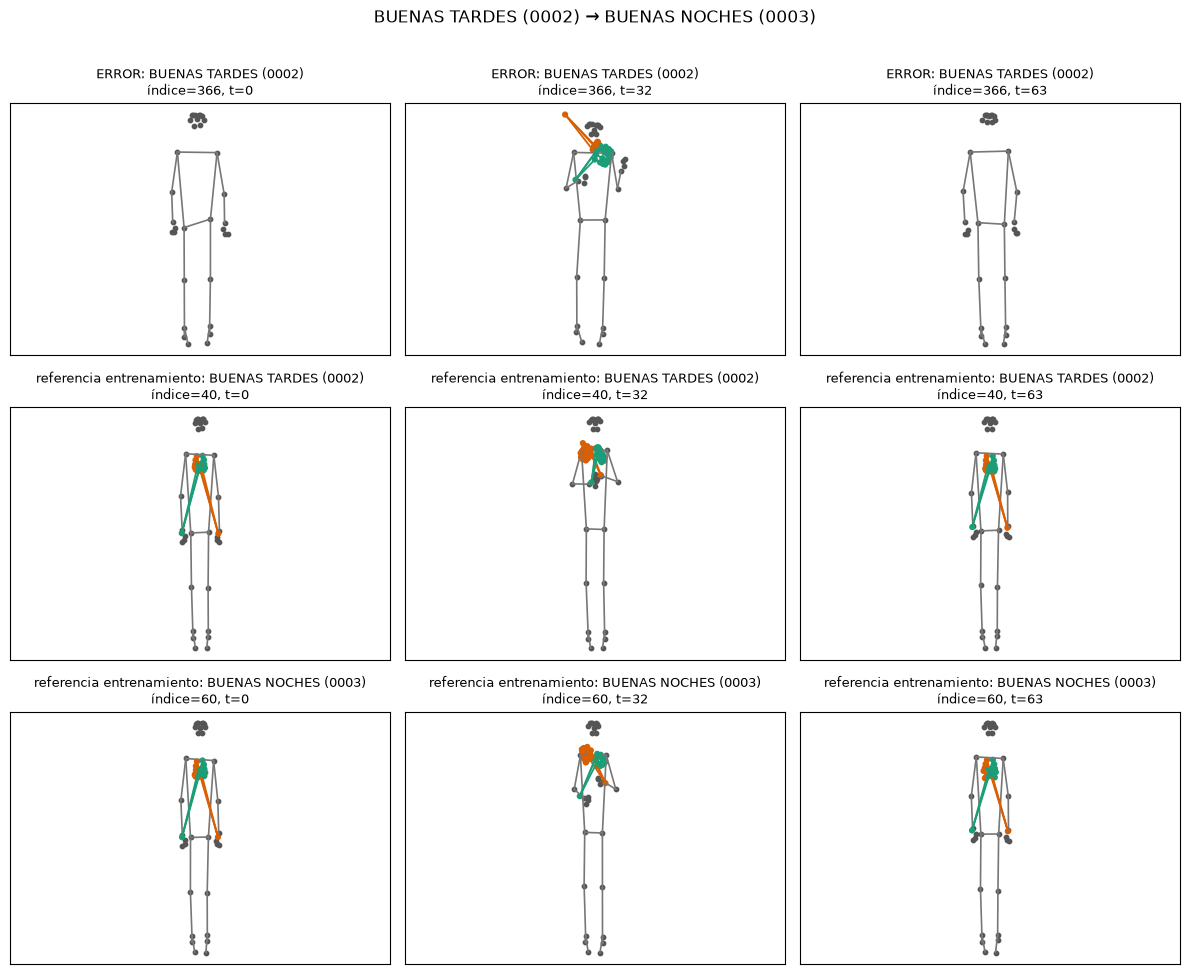

In [5]:
CASE_STUDY_LIMIT = 4
from landmark_recognition.data import normalize_landmark_sequence

POSE_EDGES = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),(23,24),(23,25),(25,27),(24,26),(26,28),(27,29),(27,31),(28,30),(28,32)]
HAND_EDGES = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),(9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]

def plot_landmark_frame(ax, sequence, frame_index, title):
    points = normalize_landmark_sequence(sequence, wrist_relative_hands=True)[frame_index]
    valid = np.any(points != 0, axis=1)
    for start, end in POSE_EDGES:
        if valid[start] and valid[end]:
            ax.plot(points[[start, end], 0], points[[start, end], 1], color="#777777", lw=1.2)
    for hand_start, color in [(33, "#d95f02"), (54, "#1b9e77")]:
        for a, b in HAND_EDGES:
            ia, ib = hand_start + a, hand_start + b
            if valid[ia] and valid[ib]:
                ax.plot(points[[ia, ib], 0], points[[ia, ib], 1], color=color, lw=1.3)
    pose_ids = np.arange(33)
    hand_ids = np.arange(33, 75)
    pose_ids = pose_ids[valid[pose_ids]]
    hand_ids = hand_ids[valid[hand_ids]]
    if len(pose_ids):
        ax.scatter(points[pose_ids, 0], points[pose_ids, 1], s=10, color="#555555")
    if len(hand_ids):
        colors = ["#d95f02" if i < 54 else "#1b9e77" for i in hand_ids]
        ax.scatter(points[hand_ids, 0], points[hand_ids, 1], s=12, c=colors)
    ax.set_title(title, fontsize=9)
    ax.invert_yaxis()
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])

def plot_sequence_strip(axs, sample_index, label):
    sequence = X[sample_index]
    frame_ids = sorted(set([0, sequence.shape[0] // 2, sequence.shape[0] - 1]))
    for ax, frame in zip(axs, frame_ids):
        plot_landmark_frame(ax, sequence, frame, f"{label}\níndice={sample_index}, t={frame}")

case_pairs = top_pairs[:CASE_STUDY_LIMIT]
for (true_code, predicted_code), _ in case_pairs:
    case_errors = [error for error in errors if error["true_class"] == true_code and error["predicted_class"] == predicted_code]
    error_index = int(case_errors[0]["sample_index"])
    examples = [(error_index, "ERROR")]
    for code in (true_code, predicted_code):
        candidates = np.flatnonzero(train_mask & (y == class_index[code]))
        if len(candidates):
            examples.append((int(candidates[0]), "referencia entrenamiento"))
    fig, axes = plt.subplots(len(examples), 3, figsize=(12, 3.2 * len(examples)))
    axes = np.atleast_2d(axes)
    for row_index, (sample_index, role) in enumerate(examples):
        code = class_codes[int(y[sample_index])]
        plot_sequence_strip(axes[row_index], sample_index, f"{role}: {display_name(code)} ({code})")
    fig.suptitle(f"{display_name(true_code)} ({true_code}) → {display_name(predicted_code)} ({predicted_code})", y=1.01)
    fig.tight_layout()
    print(f"Índice(s) de error: {[error['sample_index'] for error in case_errors]}; firmante={test_signer}")
    plt.show()
if not case_pairs:
    print("El checkpoint no tuvo errores en este conjunto de prueba.")

## 4. Similitud matemática entre las clases confundidas

Cada secuencia se normaliza (centrado por hombros y manos relativas a muñeca). Se resume con media y desviación temporal por landmark, además de velocidad absoluta media. 


Par | n entrenamiento | distancia centros | dispersión intra | entre/intra | coseno | |d| medio
MÁS O MENOS → CHAO | 42/49 | 4.02 | 5.02 | 0.80 | 0.98 | 0.62
PERMISO → DE NADA | 42/49 | 3.48 | 3.99 | 0.87 | 0.99 | 0.89
BUENAS TARDES → BUENAS NOCHES | 69/71 | 1.26 | 3.85 | 0.33 | 1.00 | 0.28

Landmarks ausentes promedio: 19.1%
Cobertura promedio: entrenamiento=82.2%; prueba=68.1%


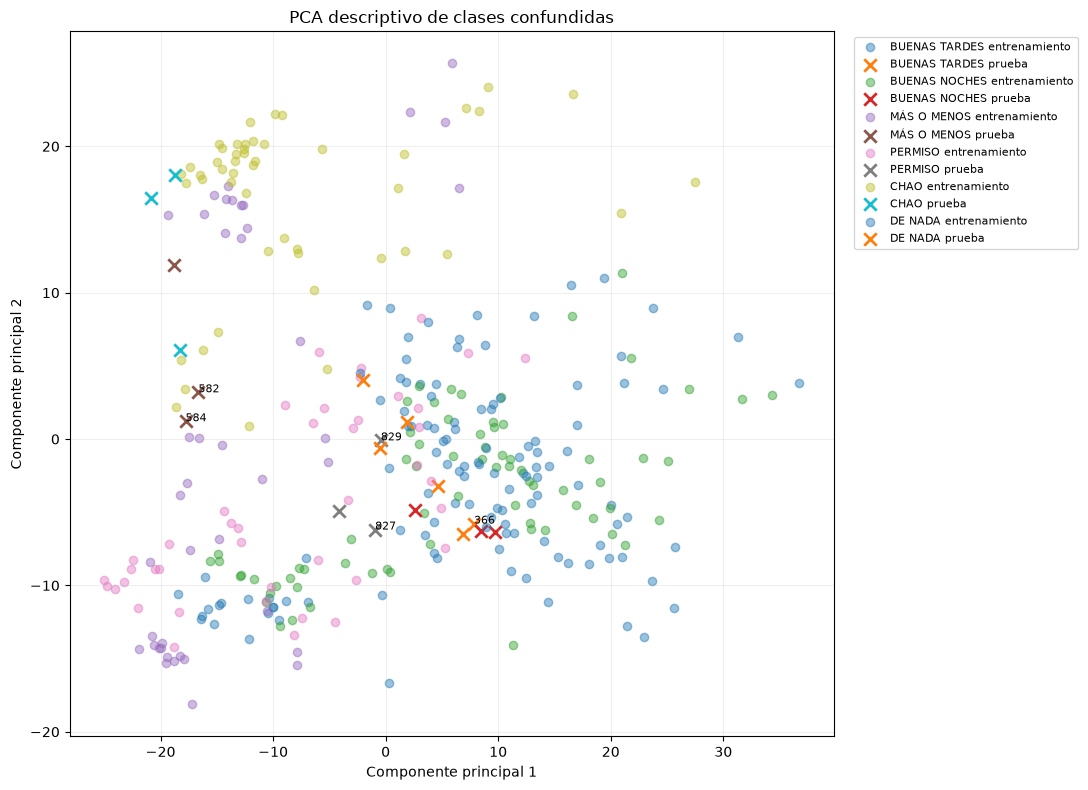

In [6]:
normalized = np.stack([normalize_landmark_sequence(sequence, wrist_relative_hands=True) for sequence in X])
temporal_mean = normalized.mean(axis=1)
temporal_std = normalized.std(axis=1)
mean_abs_velocity = np.abs(np.diff(normalized, axis=1)).mean(axis=1)
descriptors = np.concatenate([temporal_mean.reshape(len(X), -1), temporal_std.reshape(len(X), -1), mean_abs_velocity.reshape(len(X), -1)], axis=1)

def describe_pair(code_a, code_b):
    ids_a = np.flatnonzero(train_mask & (y == class_index[code_a]))
    ids_b = np.flatnonzero(train_mask & (y == class_index[code_b]))
    if len(ids_a) < 2 or len(ids_b) < 2:
        return None
    a, b = descriptors[ids_a], descriptors[ids_b]
    center_a, center_b = a.mean(axis=0), b.mean(axis=0)
    between = float(np.linalg.norm(center_a - center_b))
    within_a = float(np.linalg.norm(a - center_a, axis=1).mean())
    within_b = float(np.linalg.norm(b - center_b, axis=1).mean())
    within = (within_a + within_b) / 2
    cosine = float(np.dot(center_a, center_b) / (np.linalg.norm(center_a) * np.linalg.norm(center_b) + 1e-12))
    pooled_var = ((len(a)-1)*a.var(axis=0, ddof=1) + (len(b)-1)*b.var(axis=0, ddof=1)) / (len(a)+len(b)-2)
    effect_size = (center_a - center_b) / np.sqrt(pooled_var + 1e-12)
    return {"a": code_a, "b": code_b, "n_a": len(a), "n_b": len(b), "between": between, "within": within, "ratio": between/(within+1e-12), "cosine": cosine, "cohen_d": float(np.mean(np.abs(effect_size)))}

pair_stats = [describe_pair(a, b) for (a, b), _ in case_pairs]
print("Par | n entrenamiento | distancia centros | dispersión intra | entre/intra | coseno | |d| medio")
for item in (item for item in pair_stats if item is not None):
    print(f"{display_name(item['a'])} → {display_name(item['b'])} | {item['n_a']}/{item['n_b']} | {item['between']:.2f} | {item['within']:.2f} | {item['ratio']:.2f} | {item['cosine']:.2f} | {item['cohen_d']:.2f}")

missing_fraction = (X == 0).all(axis=-1).mean(axis=(1, 2))
coverage = (X != 0).any(axis=-1).mean(axis=(1, 2))
print(f"\nLandmarks ausentes promedio: {missing_fraction.mean():.1%}")
print(f"Cobertura promedio: entrenamiento={coverage[train_mask].mean():.1%}; prueba={coverage[test_mask].mean():.1%}")

# Proyección PCA: escalado y ajuste usando solo ejemplos de entrenamiento.
focus_codes = sorted(set(code for (a, b), _ in case_pairs for code in (a, b)))
focus_indices = np.flatnonzero((train_mask | test_mask) & np.isin(y, [class_index[code] for code in focus_codes]))
fit_mask = train_mask[focus_indices]
if len(focus_indices) >= 2 and fit_mask.sum() >= 2:
    fit = descriptors[focus_indices][fit_mask]
    mean = fit.mean(axis=0)
    scale = fit.std(axis=0)
    scale[scale < 1e-8] = 1.0
    standardized = (descriptors[focus_indices] - mean) / scale
    center = standardized[fit_mask].mean(axis=0)
    _, _, components = np.linalg.svd(standardized - center, full_matrices=False)
    coordinates = (standardized - center) @ components[:2].T
    fig, ax = plt.subplots(figsize=(11, 8))
    for code in focus_codes:
        selected = y[focus_indices] == class_index[code]
        is_test = test_mask[focus_indices[selected]]
        points = coordinates[selected]
        ax.scatter(points[~is_test, 0], points[~is_test, 1], alpha=.45, label=f"{display_name(code)} entrenamiento")
        ax.scatter(points[is_test, 0], points[is_test, 1], marker="x", s=80, linewidth=2, label=f"{display_name(code)} prueba")
    positions = {int(index): pos for pos, index in enumerate(focus_indices)}
    for error in errors:
        index = error["sample_index"]
        if index in positions:
            point = coordinates[positions[index]]
            ax.annotate(str(index), point, fontsize=8)
    ax.set(title="PCA descriptivo de clases confundidas", xlabel="Componente principal 1", ylabel="Componente principal 2")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("PCA omitido: no hay suficientes ejemplos de entrenamiento en las clases con errores.")

## 5. Variación entre firmantes y conclusiones

La siguiente medida contrasta el centroide de descriptores de entrenamiento de cada clase con el del firmante reservado, escalando por la dispersión de entrenamiento.

In [7]:
domain_rows = []
for code in focus_codes:
    train_ids = np.flatnonzero(train_mask & (y == class_index[code]))
    test_ids = np.flatnonzero(test_mask & (y == class_index[code]))
    if not len(train_ids) or not len(test_ids):
        continue
    train_features = descriptors[train_ids]
    test_features = descriptors[test_ids]
    scale = np.sqrt(train_features.var(axis=0) + 1e-8)
    shift = float(np.linalg.norm((test_features.mean(axis=0) - train_features.mean(axis=0)) / scale) / np.sqrt(descriptors.shape[1]))
    domain_rows.append((shift, code, len(train_ids), len(test_ids), coverage[train_ids].mean(), coverage[test_ids].mean()))
print("Desplazamiento entrenamiento → firmante reservado:")
for shift, code, n_train, n_test, cov_train, cov_test in sorted(domain_rows, reverse=True):
    print(f"{display_name(code):20s} {code} | n={n_train}/{n_test} | desplazamiento={shift:.2f} | cobertura={cov_train:.1%}/{cov_test:.1%}")

print("\nSÍNTESIS — evidencia observada")
print(f"- El checkpoint obtuvo {len(test_indices)-len(errors)}/{len(test_indices)} aciertos (accuracy={accuracy:.1%}) para el firmante reservado {test_signer}.")
print(f"- Se observaron {len(errors)} errores entre {len(test_indices)} secuencias y {len(set(test_targets))} clases con ejemplos de prueba.")
if top_pairs:
    (a, b), count = top_pairs[0]
    print(f"- La confusión más frecuente fue {display_name(a)} ({a}) → {display_name(b)} ({b}), con {count} caso(s).")
print("\nHIPÓTESIS PARA CONTRASTAR:")
print("1. Centroides cercanos o PCA solapado pueden indicar descriptores de landmarks parecidos.")
print("2. Baja cobertura puede señalar oclusión o landmarks no detectados.")
print("3. Un desplazamiento alto entre firmantes es compatible con variación de ejecución, pero no determina su causa.")


Desplazamiento entrenamiento → firmante reservado:
PERMISO              0036 | n=42/3 | desplazamiento=0.96 | cobertura=89.3%/75.5%
DE NADA              0052 | n=49/3 | desplazamiento=0.92 | cobertura=80.8%/78.0%
BUENAS NOCHES        0003 | n=71/3 | desplazamiento=0.85 | cobertura=88.0%/76.8%
MÁS O MENOS          0027 | n=42/3 | desplazamiento=0.85 | cobertura=82.6%/59.5%
CHAO                 0051 | n=49/3 | desplazamiento=0.76 | cobertura=70.1%/61.1%
BUENAS TARDES        0002 | n=69/3 | desplazamiento=0.73 | cobertura=87.7%/75.8%

SÍNTESIS — evidencia observada
- El checkpoint obtuvo 46/51 aciertos (accuracy=90.2%) para el firmante reservado courtesy_videos::0025.
- Se observaron 5 errores entre 51 secuencias y 17 clases con ejemplos de prueba.
- La confusión más frecuente fue MÁS O MENOS (0027) → CHAO (0051), con 2 caso(s).

HIPÓTESIS PARA CONTRASTAR:
1. Centroides cercanos o PCA solapado pueden indicar descriptores de landmarks parecidos.
2. Baja cobertura puede señalar oclusión o l

## 6. Evidencia adicional: incertidumbre, cobertura y similitud por error



Accuracy del firmante reservado y Wilson 95%:
90.2% [79.0%, 95.7%], n=51
Bootstrap estratificado por clase (95% percentil, 5.000 r?plicas; incertidumbre de esta prueba):
accuracy=0.902, IC=[0.843, 0.961]
F1 macro=0.892, IC=[0.799, 0.960]
Recall por clase con intervalo Wilson (muestra de prueba peque?a):


,codigo,clase,soporte,aciertos,recall,IC95_inf,IC95_sup,errores
6,0027,MÁS O MENOS,3,1,0.333,0.061,0.792,2
12,0036,PERMISO,3,1,0.333,0.061,0.792,2
2,0002,BUENAS TARDES,3,2,0.667,0.208,0.939,1
0,0000,GRACIAS,3,3,1.000,0.439,1.000,0
1,0001,BUENOS DÍAS,3,3,1.000,0.439,1.000,0
3,0003,BUENAS NOCHES,3,3,1.000,0.439,1.000,0
4,0024,BIEN,3,3,1.000,0.439,1.000,0
5,0025,MAL,3,3,1.000,0.439,1.000,0
7,0030,HOLA,3,3,1.000,0.439,1.000,0
8,0032,POR FAVOR,3,3,1.000,0.439,1.000,0


Diagn?stico muestra por muestra: p_real baja/rango alto significa que la etiqueta real ni siquiera compite entre las primeras; margen alto en un error significa preferencia clara del checkpoint por la clase equivocada.


,indice,clase_real,prediccion,acierto,p_top1,p_top2,margen_top1_top2,p_clase_real,rango_clase_real,cobertura_pose,cobertura_mano_izquierda,cobertura_mano_derecha,movimiento_pose,movimiento_manos
38,829,0036,0052,False,0.586,0.320,0.266,0.320,2,1.0,0.594,0.406,0.146,0.067
20,584,0027,0051,False,0.483,0.182,0.302,0.182,2,1.0,0.531,0.000,0.088,0.028
36,827,0036,0052,False,0.635,0.175,0.459,0.175,2,1.0,0.406,0.672,0.148,0.078
7,366,0002,0003,False,0.851,0.054,0.796,0.054,2,1.0,0.516,0.484,0.180,0.091
18,582,0027,0051,False,0.837,0.031,0.806,0.028,4,1.0,0.516,0.000,0.099,0.024
15,529,0025,0025,True,0.419,0.290,0.129,0.419,1,1.0,0.641,0.000,0.109,0.021
8,367,0002,0002,True,0.446,0.266,0.180,0.446,1,1.0,0.562,0.609,0.181,0.097
34,773,0035,0035,True,0.363,0.144,0.219,0.363,1,1.0,0.641,0.719,0.144,0.106
35,774,0035,0035,True,0.519,0.219,0.300,0.519,1,1.0,0.375,0.594,0.113,0.090
1,284,0000,0000,True,0.603,0.258,0.345,0.603,1,1.0,0.688,0.188,0.200,0.102


Promedios entre aciertos y errores (descriptivos; no causales):


,cobertura_pose,cobertura_mano_izquierda,cobertura_mano_derecha,movimiento_pose,movimiento_manos
acierto,,,,,
error,1.0,0.512,0.312,0.132,0.058
acierto,1.0,0.394,0.469,0.123,0.052


?El descriptor global de landmarks del error se parece m?s al centroide de la clase predicha?:


,indice,real,predicha,distancia_centroide_real,distancia_centroide_predicha,mas_cercana_a_predicha,margen_clasificador
0,366,0002,0003,0.742,0.758,False,0.796
1,582,0027,0051,1.088,1.263,False,0.806
2,584,0027,0051,1.027,1.231,False,0.302
3,827,0036,0052,1.030,1.086,False,0.459
4,829,0036,0052,1.031,0.987,True,0.266


M?s cercano al centroide predicho: 1/5 errores. Esto no sustituye explicaciones del Transformer; solo contrasta similitud geom?trica/temporal.


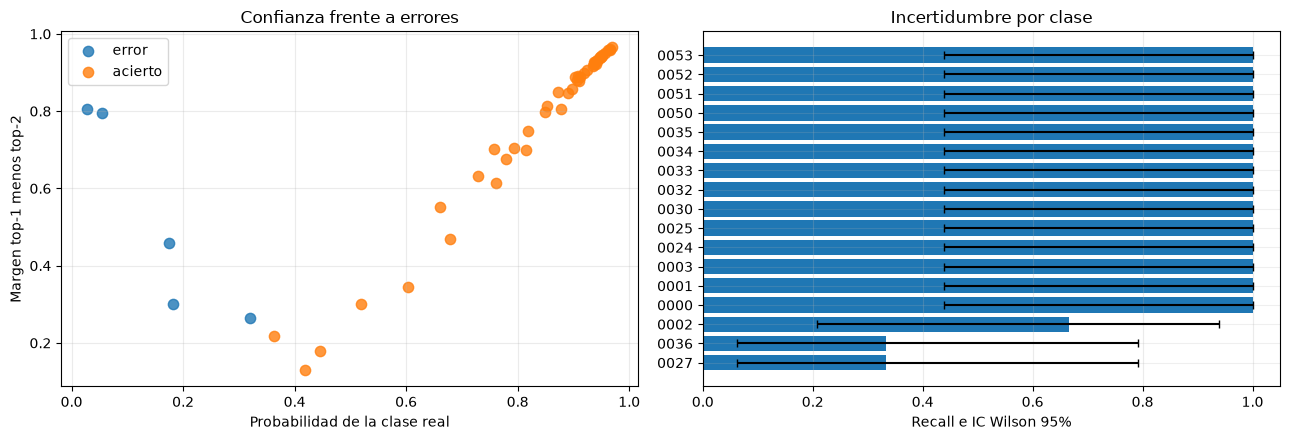

L?mite de evidencia: el conjunto reservado contiene un solo firmante (3 tomas/clase). Para sostener una causa general, repetir la evaluaci?n con varios firmantes nunca vistos y verificar etiquetas/landmarks en video original.


In [8]:
import pandas as pd


def wilson_interval(successes, total, z=1.959963984540054):
    if total == 0:
        return (np.nan, np.nan)
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return max(0.0, center - half_width), min(1.0, center + half_width)


def macro_f1_from_predictions(targets, predicted, class_count):
    matrix = np.zeros((class_count, class_count), dtype=np.int64)
    np.add.at(matrix, (targets, predicted), 1)
    true_positive = np.diag(matrix)
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    class_f1 = np.divide(2 * true_positive, denominator, out=np.zeros(class_count, dtype=float), where=denominator > 0)
    return float(class_f1.mean())


# Confianza y rango de la etiqueta real; Softmax no es una probabilidad calibrada.
ranked_indices = np.argsort(probabilities, axis=1)[:, ::-1]
top1_indices = ranked_indices[:, 0]
top2_indices = ranked_indices[:, 1]
top1_probability = probabilities[np.arange(len(test_targets)), top1_indices]
top2_probability = probabilities[np.arange(len(test_targets)), top2_indices]
true_probability = probabilities[np.arange(len(test_targets)), test_targets]
true_rank = 1 + (probabilities > true_probability[:, None]).sum(axis=1)
normalized_test = normalized[test_indices]
valid_landmarks = np.any(np.abs(X[test_indices]) > 1e-8, axis=-1)
landmark_delta = np.diff(normalized_test, axis=1)
landmark_speed = np.linalg.norm(landmark_delta, axis=-1)

sample_evidence = []
for row_index, sample_index in enumerate(test_indices):
    sample_evidence.append({
        "indice": int(sample_index),
        "clase_real": class_codes[int(test_targets[row_index])],
        "prediccion": class_codes[int(test_predictions[row_index])],
        "acierto": bool(test_predictions[row_index] == test_targets[row_index]),
        "p_top1": float(top1_probability[row_index]),
        "p_top2": float(top2_probability[row_index]),
        "margen_top1_top2": float(top1_probability[row_index] - top2_probability[row_index]),
        "p_clase_real": float(true_probability[row_index]),
        "rango_clase_real": int(true_rank[row_index]),
        "cobertura_pose": float(valid_landmarks[row_index, :, :33].mean()),
        "cobertura_mano_izquierda": float(valid_landmarks[row_index, :, 33:54].mean()),
        "cobertura_mano_derecha": float(valid_landmarks[row_index, :, 54:75].mean()),
        "movimiento_pose": float(landmark_speed[row_index, :, :33].mean()),
        "movimiento_manos": float(landmark_speed[row_index, :, 33:75].mean()),
    })
evidence_df = pd.DataFrame(sample_evidence)
print("Accuracy del firmante reservado y Wilson 95%:")
accuracy_ci = wilson_interval(int(np.sum(test_predictions == test_targets)), len(test_targets))
print(f"{np.mean(test_predictions == test_targets):.1%} [{accuracy_ci[0]:.1%}, {accuracy_ci[1]:.1%}], n={len(test_targets)}")

rng = np.random.default_rng(20261115)
class_positions = [np.flatnonzero(test_targets == class_id) for class_id in range(len(class_codes))]
class_positions = [indices for indices in class_positions if len(indices)]
bootstrap_accuracy = np.empty(5000, dtype=float)
bootstrap_macro_f1 = np.empty(5000, dtype=float)
for replicate in range(len(bootstrap_accuracy)):
    sampled_positions = np.concatenate([
        rng.choice(indices, size=len(indices), replace=True) for indices in class_positions
    ])
    sampled_targets = test_targets[sampled_positions]
    sampled_predictions = test_predictions[sampled_positions]
    bootstrap_accuracy[replicate] = np.mean(sampled_targets == sampled_predictions)
    bootstrap_macro_f1[replicate] = macro_f1_from_predictions(sampled_targets, sampled_predictions, len(class_codes))
print("Bootstrap estratificado por clase (95% percentil, 5.000 r?plicas; incertidumbre de esta prueba):")
print(f"accuracy={np.mean(test_predictions == test_targets):.3f}, IC=[{np.quantile(bootstrap_accuracy, .025):.3f}, {np.quantile(bootstrap_accuracy, .975):.3f}]")
print(f"F1 macro={macro_f1_from_predictions(test_targets, test_predictions, len(class_codes)):.3f}, IC=[{np.quantile(bootstrap_macro_f1, .025):.3f}, {np.quantile(bootstrap_macro_f1, .975):.3f}]")

class_rows = []
for class_id, code in enumerate(class_codes):
    mask = test_targets == class_id
    support = int(mask.sum())
    if not support:
        continue
    successes = int(np.sum(test_predictions[mask] == class_id))
    lower, upper = wilson_interval(successes, support)
    class_rows.append({
        "codigo": code,
        "clase": display_name(code),
        "soporte": support,
        "aciertos": successes,
        "recall": successes / support,
        "IC95_inf": lower,
        "IC95_sup": upper,
        "errores": support - successes,
    })
class_evidence_df = pd.DataFrame(class_rows).sort_values(["recall", "codigo"])
print("Recall por clase con intervalo Wilson (muestra de prueba peque?a):")
display(class_evidence_df.round(3))

print("Diagn?stico muestra por muestra: p_real baja/rango alto significa que la etiqueta real ni siquiera compite entre las primeras; margen alto en un error significa preferencia clara del checkpoint por la clase equivocada.")
display(evidence_df.sort_values(["acierto", "margen_top1_top2"])[[
    "indice", "clase_real", "prediccion", "acierto", "p_top1", "p_top2",
    "margen_top1_top2", "p_clase_real", "rango_clase_real",
    "cobertura_pose", "cobertura_mano_izquierda", "cobertura_mano_derecha",
    "movimiento_pose", "movimiento_manos",
]].round(3))

error_coverage = evidence_df.groupby("acierto")[["cobertura_pose", "cobertura_mano_izquierda", "cobertura_mano_derecha", "movimiento_pose", "movimiento_manos"]].mean()
print("Promedios entre aciertos y errores (descriptivos; no causales):")
display(error_coverage.rename(index={False: "error", True: "acierto"}).round(3))

# Descriptor auxiliar de forma y din?mica; centroides calculados ?nicamente con train_mask.
all_motion = np.abs(np.diff(normalized, axis=1)).mean(axis=1)
train_descriptors = np.concatenate([
    normalized.mean(axis=1).reshape(len(X), -1),
    normalized.std(axis=1).reshape(len(X), -1),
    all_motion.reshape(len(X), -1),
], axis=1)
pooled_scale = np.std(train_descriptors[train_mask], axis=0)
pooled_scale = np.maximum(pooled_scale, 1e-4)
centroids = {}
for code in class_codes:
    class_train_ids = np.flatnonzero(train_mask & (y == class_index[code]))
    if len(class_train_ids):
        centroids[code] = train_descriptors[class_train_ids].mean(axis=0)

centroid_rows = []
for row_index, sample_index in enumerate(test_indices):
    if test_predictions[row_index] == test_targets[row_index]:
        continue
    true_code = class_codes[int(test_targets[row_index])]
    predicted_code = class_codes[int(test_predictions[row_index])]
    sample_descriptor = train_descriptors[int(sample_index)]
    distance_true = float(np.sqrt(np.mean(((sample_descriptor - centroids[true_code]) / pooled_scale) ** 2)))
    distance_predicted = float(np.sqrt(np.mean(((sample_descriptor - centroids[predicted_code]) / pooled_scale) ** 2)))
    centroid_rows.append({
        "indice": int(sample_index),
        "real": true_code,
        "predicha": predicted_code,
        "distancia_centroide_real": distance_true,
        "distancia_centroide_predicha": distance_predicted,
        "mas_cercana_a_predicha": distance_predicted < distance_true,
        "margen_clasificador": float(top1_probability[row_index] - top2_probability[row_index]),
    })
centroid_evidence_df = pd.DataFrame(centroid_rows)
print("?El descriptor global de landmarks del error se parece m?s al centroide de la clase predicha?:")
display(centroid_evidence_df.round(3))
if not centroid_evidence_df.empty:
    print(f"M?s cercano al centroide predicho: {int(centroid_evidence_df['mas_cercana_a_predicha'].sum())}/{len(centroid_evidence_df)} errores. Esto no sustituye explicaciones del Transformer; solo contrasta similitud geom?trica/temporal.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for is_correct, group in evidence_df.groupby("acierto"):
    axes[0].scatter(group["p_clase_real"], group["margen_top1_top2"], label="acierto" if is_correct else "error", s=55, alpha=.8)
axes[0].set(xlabel="Probabilidad de la clase real", ylabel="Margen top-1 menos top-2", title="Confianza frente a errores")
axes[0].legend()
axes[0].grid(alpha=.25)
axes[1].barh(class_evidence_df["codigo"], class_evidence_df["recall"], xerr=[class_evidence_df["recall"] - class_evidence_df["IC95_inf"], class_evidence_df["IC95_sup"] - class_evidence_df["recall"]], capsize=3)
axes[1].set(xlim=(0, 1.05), xlabel="Recall e IC Wilson 95%", title="Incertidumbre por clase")
axes[1].grid(axis="x", alpha=.25)
fig.tight_layout()
plt.show()

print("L?mite de evidencia: el conjunto reservado contiene un solo firmante (3 tomas/clase). Para sostener una causa general, repetir la evaluaci?n con varios firmantes nunca vistos y verificar etiquetas/landmarks en video original.")